# EBM basado en energía — Denoising Score Matching multiescala en MNIST

In [1]:
import sys
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    project_root = Path.cwd().parents[0]
else:
    drive.mount("/content/drive", force_remount=True)
    project_root = Path("/content/drive/MyDrive/tfg_copia")

assert (project_root / "ebm").is_dir(), f"raíz mal resuelta: {project_root}"
sys.path.insert(0, str(project_root))
print("Project root:", project_root)

import time
import json
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.utils import save_image
import matplotlib.pyplot as plt

from data import get_mnist_loaders

from ebm.models import EnergyUNet
from ebm.sampling import (
    annealed_langevin,
    langevin_at_sigma,
)
from ebm.noise import build_noise_schedule
from ebm.training import train_energy_model_dsm

from utils import (
    plot_image_grid,
    plot_image_evolution,
)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("device:", device)

Mounted at /content/drive
Project root: /content/drive/MyDrive/tfg_copia
DATA_DIR: /content/drive/MyDrive/tfg_copia/data
device: cuda


## Configuración

In [2]:
QUICK_TEST = False

CFG = dict(
    seed            = 42,
    # datos
    batch_size      = 128,
    # niveles de ruido
    sigma_1         = "auto",
    sigma_L         = 0.01,
    overlap_C       = 0.5,
    # muestreo
    T               = 5,
    eps             = "auto",
    # red
    channels        = 64,
    # optimización
    lr              = 1e-4,
    grad_clip       = 1.0,
    ema_decay       = 0.999,
    epochs          = 60,
    max_iters_per_epoch = None,
    # monitorización
    vis_every       = 5,
    ckpt_dir        = str(
        project_root / "checkpoints" / "energy_dsm"
    ),
    pcd_samples_path = str(project_root / "results" / "pcd" / "muestras_pcd_01.pt"),
    score_samples_path = str(project_root / "results" / "dsm" / "muestras_dsm_01.pt"),
    # resultados
    results_dir     = str(
        project_root / "results" / "energy_dsm"
    ),
    only_last = True
)

if QUICK_TEST:
    CFG.update(
        epochs=2,
        max_iters_per_epoch=30,
        vis_every=1,
        T=1,
    )

set_seed(CFG["seed"])

IMG_SHAPE = (1, 28, 28)

CFG

{'seed': 42,
 'batch_size': 128,
 'sigma_1': 'auto',
 'sigma_L': 0.01,
 'overlap_C': 0.5,
 'T': 5,
 'eps': 'auto',
 'channels': 64,
 'lr': 0.0001,
 'grad_clip': 1.0,
 'ema_decay': 0.999,
 'epochs': 60,
 'max_iters_per_epoch': None,
 'vis_every': 5,
 'ckpt_dir': '/content/drive/MyDrive/tfg_copia/checkpoints/energy_dsm',
 'pcd_samples_path': '/content/drive/MyDrive/tfg_copia/results/pcd/muestras_pcd_01.pt',
 'score_samples_path': '/content/drive/MyDrive/tfg_copia/results/dsm/muestras_dsm_01.pt',
 'results_dir': '/content/drive/MyDrive/tfg_copia/results/energy_dsm',
 'only_last': True}

## Datos

In [3]:
train_loader, test_loader = get_mnist_loaders(
    batch_size=CFG["batch_size"],
    normalize=False,
    num_workers=2,
)

x_real, _ = next(iter(train_loader))

print(
    x_real.shape,
    x_real.min().item(),
    x_real.max().item(),
)

torch.Size([128, 1, 28, 28]) 0.0 1.0


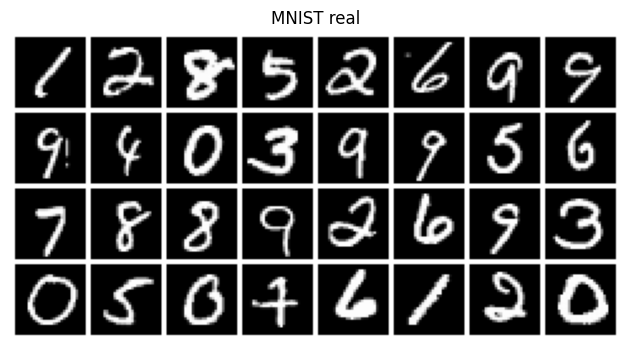

In [4]:
fig, ax = plot_image_grid(
    images=x_real[:32],
    figsize=(8, 4),
    n_cols=8,
)

ax.set_title("MNIST real")
plt.show()

## Niveles de ruido

Se utiliza `build_noise_schedule` igual que en `ebm_denoising`: cálculo automático de $\sigma_1$, niveles, $\gamma$ y paso $\varepsilon$.

distancia máxima ≈ 16.88 | mediana ≈ 10.22
gamma = 1.0814 (solapamiento 0.51) | L = 96 niveles
T = 5 | eps = 1.105e-05 | Ec.(4) = 1.093 (ideal 1)
evaluaciones de la red por muestra: 481


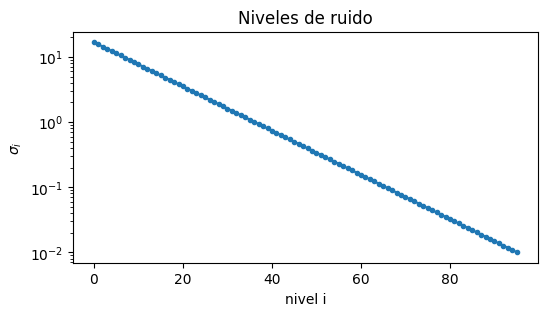

In [5]:
noise_schedule = build_noise_schedule(
    dataset=train_loader.dataset,
    image_shape=IMG_SHAPE,
    device=device,
    sigma_1=CFG["sigma_1"],
    sigma_l=CFG["sigma_L"],
    overlap_c=CFG["overlap_C"],
    n_steps_per_level=CFG["T"],
    eps=CFG["eps"],
)

sigmas = noise_schedule["sigmas"]
sigma_1 = noise_schedule["sigma_1"]
sigma_L = noise_schedule["sigma_l"]
gamma = noise_schedule["gamma"]
L = noise_schedule["n_levels"]
eps = noise_schedule["eps"]
NFE = noise_schedule["nfe"]

print(
    f"distancia máxima ≈ {noise_schedule['dmax']:.2f} | "
    f"mediana ≈ {noise_schedule['dmed']:.2f}"
)

print(
    f"gamma = {gamma:.4f} "
    f"(solapamiento {noise_schedule['overlap']:.2f}) | "
    f"L = {L} niveles"
)

print(
    f"T = {CFG['T']} | "
    f"eps = {eps:.3e} | "
    f"Ec.(4) = {noise_schedule['eq4_ratio']:.3f} "
    "(ideal 1)"
)

print(
    f"evaluaciones de la red por muestra: {NFE}"
)

plt.figure(figsize=(6, 3))
plt.semilogy(
    sigmas.cpu().numpy(),
    ".-",
)
plt.xlabel("nivel i")
plt.ylabel(r"$\sigma_i$")
plt.title("Niveles de ruido")
plt.show()


## Red de energía

`EnergyUNet` está definida en `ebm/models/energy_unet.py`. La arquitectura, el condicionamiento por ruido y la función de energía son los del notebook original. No se define la red de nuevo aquí para mantener el notebook modular.

La energía por imagen es $E_\theta(x,\sigma)$; `model(x, sigma)` obtiene $-\nabla_x E_\theta(x,\sigma)$. Así, el entrenador DSM y los muestreadores reciben la misma interfaz que con `ScoreUNet`. **El cálculo de los gradientes del score respecto a los parámetros implica derivadas de segundo orden y puede aumentar el coste de memoria y tiempo.**

In [6]:
model = EnergyUNet(
    channels=CFG["channels"],
).to(device)

ema = copy.deepcopy(
    model
).eval()

for parameter in ema.parameters():
    parameter.requires_grad_(False)

print(model)
print(
    "parámetros:",
    sum(
        parameter.numel()
        for parameter
        in model.parameters()
    ),
)


EnergyUNet(
  (embed): Sequential(
    (0): FourierEmbedding()
    (1): Linear(in_features=128, out_features=128, bias=True)
    (2): SiLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
  )
  (conv_in): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (enc1): ResBlock(
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (emb): Linear(in_features=128, out_features=64, bias=True)
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (skip): Identity()
    (act): SiLU()
  )
  (down1): Conv2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (enc2): ResBlock(
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (emb): Linear(in_features=128, out_features=128, bias=True)
    (norm2): GroupNorm(8, 

## Muestreador Langevin recocido

Se reutiliza `ebm.sampling.annealed_langevin` porque `EnergyUNet.forward(x, sigma)` devuelve el score.

In [7]:
sampler_kwargs = dict(
    sigmas=sigmas,
    eps=eps,
    image_shape=IMG_SHAPE,
    n_steps_per_level=CFG["T"],
    device=device,
)

## Entrenamiento

In [10]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=CFG["lr"],
)

hist_it = {
    "loss": [],
}

hist_ep = {
    key: []
    for key in [
        "epoch",
        "loss",
        "loss_per_sigma",
        "time_s",
    ]
}

# Mismo ruido inicial para comparar las muestras entre épocas.
generator = torch.Generator(
    device=device
).manual_seed(1234)

vis_init = (
    torch.rand(
        16,
        *IMG_SHAPE,
        generator=generator,
        device=device,
    )
    + sigmas[0]
    * torch.randn(
        16,
        *IMG_SHAPE,
        generator=generator,
        device=device,
    )
)


época   1/60 |   30.6s | loss  119.5008 | loss(σ grande)  10.5690 | loss(σ pequeño) 258.8570
época   2/60 |   27.3s | loss   56.7661 | loss(σ grande)   5.3982 | loss(σ pequeño) 119.6819
época   3/60 |   27.6s | loss   50.3471 | loss(σ grande)   4.7743 | loss(σ pequeño) 105.4464
época   4/60 |   27.3s | loss   48.0035 | loss(σ grande)   4.4115 | loss(σ pequeño) 101.0573
época   5/60 |   27.4s | loss   45.9232 | loss(σ grande)   4.3745 | loss(σ pequeño)  97.8844


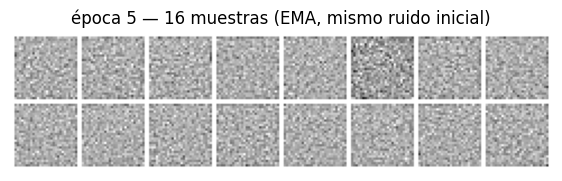

época   6/60 |   27.5s | loss   44.9847 | loss(σ grande)   4.0962 | loss(σ pequeño)  95.7496
época   7/60 |   27.4s | loss   43.8430 | loss(σ grande)   4.0023 | loss(σ pequeño)  94.4285
época   8/60 |   27.4s | loss   43.5720 | loss(σ grande)   3.9549 | loss(σ pequeño)  93.6702
época   9/60 |   27.9s | loss   43.0926 | loss(σ grande)   3.9521 | loss(σ pequeño)  92.3956
época  10/60 |   27.7s | loss   42.3809 | loss(σ grande)   3.8840 | loss(σ pequeño)  92.0451


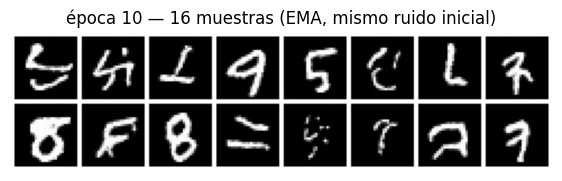

época  11/60 |   27.4s | loss   42.5731 | loss(σ grande)   3.8259 | loss(σ pequeño)  91.5553
época  12/60 |   27.8s | loss   42.1958 | loss(σ grande)   3.8231 | loss(σ pequeño)  90.8778
época  13/60 |   27.4s | loss   41.8000 | loss(σ grande)   3.7718 | loss(σ pequeño)  90.7151
época  14/60 |   27.2s | loss   41.8773 | loss(σ grande)   3.7638 | loss(σ pequeño)  90.6232
época  15/60 |   27.9s | loss   41.6754 | loss(σ grande)   3.7497 | loss(σ pequeño)  90.0689


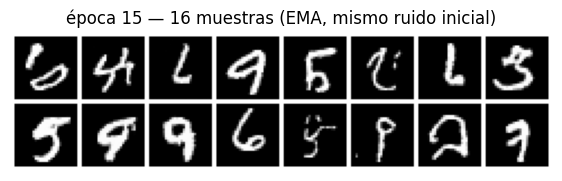

época  16/60 |   27.8s | loss   41.2349 | loss(σ grande)   3.7251 | loss(σ pequeño)  89.6477
época  17/60 |   27.5s | loss   40.9645 | loss(σ grande)   3.7072 | loss(σ pequeño)  89.1062
época  18/60 |   27.8s | loss   40.8746 | loss(σ grande)   3.6868 | loss(σ pequeño)  89.1185
época  19/60 |   27.3s | loss   40.7094 | loss(σ grande)   3.6858 | loss(σ pequeño)  88.6910
época  20/60 |   27.3s | loss   40.8425 | loss(σ grande)   3.6654 | loss(σ pequeño)  88.8402


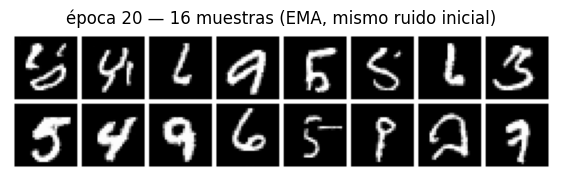

época  21/60 |   27.7s | loss   40.4078 | loss(σ grande)   3.6892 | loss(σ pequeño)  88.6107
época  22/60 |   27.5s | loss   40.4811 | loss(σ grande)   3.6740 | loss(σ pequeño)  88.4712
época  23/60 |   27.3s | loss   40.3098 | loss(σ grande)   3.6220 | loss(σ pequeño)  88.1042
época  24/60 |   27.4s | loss   40.1461 | loss(σ grande)   3.6359 | loss(σ pequeño)  87.7394
época  25/60 |   27.2s | loss   40.3358 | loss(σ grande)   3.6538 | loss(σ pequeño)  87.7833


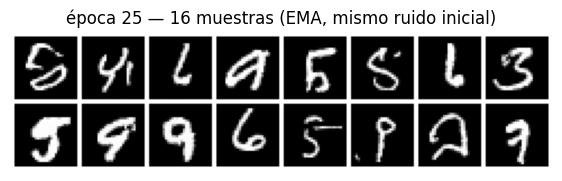

época  26/60 |   28.0s | loss   40.2240 | loss(σ grande)   3.6244 | loss(σ pequeño)  87.5278
época  27/60 |   28.1s | loss   40.2000 | loss(σ grande)   3.6364 | loss(σ pequeño)  87.6081
época  28/60 |   27.3s | loss   40.0384 | loss(σ grande)   3.6000 | loss(σ pequeño)  87.3850
época  29/60 |   27.3s | loss   39.8904 | loss(σ grande)   3.6136 | loss(σ pequeño)  86.9622
época  30/60 |   27.6s | loss   40.0352 | loss(σ grande)   3.5833 | loss(σ pequeño)  87.2640


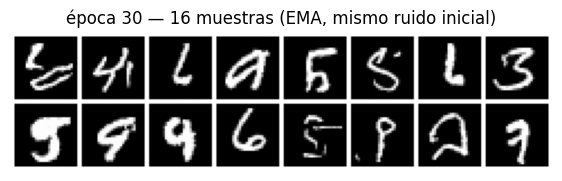

época  31/60 |   27.4s | loss   39.9116 | loss(σ grande)   3.6106 | loss(σ pequeño)  87.0872
época  32/60 |   27.3s | loss   40.0169 | loss(σ grande)   3.5881 | loss(σ pequeño)  86.8021
época  33/60 |   27.6s | loss   39.7394 | loss(σ grande)   3.5672 | loss(σ pequeño)  87.0989
época  34/60 |   27.2s | loss   39.5500 | loss(σ grande)   3.5635 | loss(σ pequeño)  86.7260
época  35/60 |   27.5s | loss   39.5373 | loss(σ grande)   3.5796 | loss(σ pequeño)  86.4724


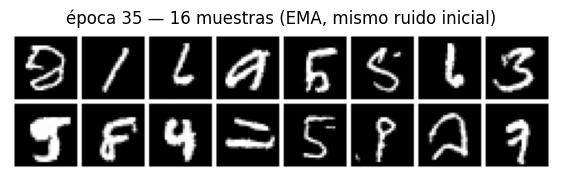

época  36/60 |   27.4s | loss   39.4629 | loss(σ grande)   3.5749 | loss(σ pequeño)  86.5780
época  37/60 |   27.5s | loss   39.2603 | loss(σ grande)   3.5730 | loss(σ pequeño)  86.3338
época  38/60 |   28.2s | loss   39.1527 | loss(σ grande)   3.5837 | loss(σ pequeño)  86.1789
época  39/60 |   27.6s | loss   39.6999 | loss(σ grande)   3.5620 | loss(σ pequeño)  86.4911
época  40/60 |   27.2s | loss   39.4565 | loss(σ grande)   3.5557 | loss(σ pequeño)  86.1021


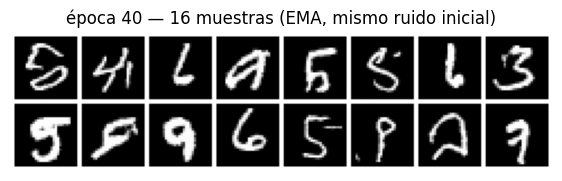

época  41/60 |   27.3s | loss   39.5162 | loss(σ grande)   3.5726 | loss(σ pequeño)  85.9713
época  42/60 |   28.2s | loss   39.3411 | loss(σ grande)   3.5480 | loss(σ pequeño)  85.7758
época  43/60 |   27.5s | loss   39.3085 | loss(σ grande)   3.5593 | loss(σ pequeño)  85.7709
época  44/60 |   27.5s | loss   39.3906 | loss(σ grande)   3.5562 | loss(σ pequeño)  86.1105
época  45/60 |   27.7s | loss   39.1935 | loss(σ grande)   3.5570 | loss(σ pequeño)  85.7604


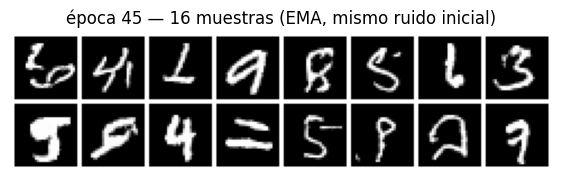

época  46/60 |   27.5s | loss   38.8230 | loss(σ grande)   3.5274 | loss(σ pequeño)  85.8784
época  47/60 |   27.2s | loss   39.0563 | loss(σ grande)   3.4982 | loss(σ pequeño)  85.7319
época  48/60 |   27.2s | loss   39.0418 | loss(σ grande)   3.5421 | loss(σ pequeño)  85.8021
época  49/60 |   27.7s | loss   39.2312 | loss(σ grande)   3.5407 | loss(σ pequeño)  85.6650
época  50/60 |   27.4s | loss   38.8556 | loss(σ grande)   3.5375 | loss(σ pequeño)  85.2616


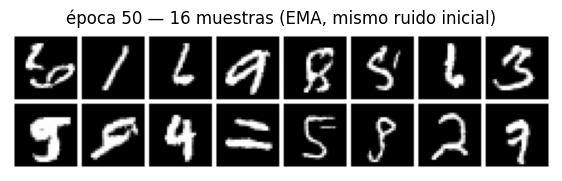

época  51/60 |   27.6s | loss   38.8902 | loss(σ grande)   3.5237 | loss(σ pequeño)  85.4559
época  52/60 |   27.4s | loss   38.6210 | loss(σ grande)   3.5340 | loss(σ pequeño)  85.2722
época  53/60 |   27.7s | loss   38.9550 | loss(σ grande)   3.5334 | loss(σ pequeño)  84.9710
época  54/60 |   28.1s | loss   38.7438 | loss(σ grande)   3.5182 | loss(σ pequeño)  84.9965
época  55/60 |   27.7s | loss   38.9483 | loss(σ grande)   3.5145 | loss(σ pequeño)  85.0684


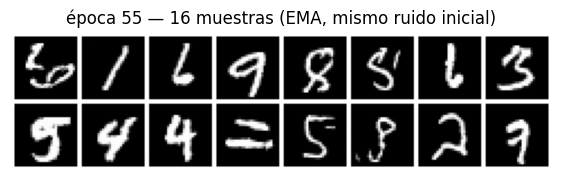

época  56/60 |   28.1s | loss   38.8998 | loss(σ grande)   3.5139 | loss(σ pequeño)  85.0476
época  57/60 |   27.7s | loss   38.7334 | loss(σ grande)   3.5486 | loss(σ pequeño)  84.8936
época  58/60 |   27.7s | loss   38.4984 | loss(σ grande)   3.5021 | loss(σ pequeño)  84.6785
época  59/60 |   27.2s | loss   38.7471 | loss(σ grande)   3.5204 | loss(σ pequeño)  84.2651
época  60/60 |   27.2s | loss   38.3470 | loss(σ grande)   3.5297 | loss(σ pequeño)  84.7034


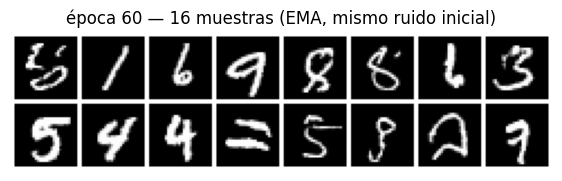

In [ ]:
hist_it, hist_ep = train_energy_model_dsm(
    model=model,
    ema=ema,
    data_loader=train_loader,
    optimizer=optimizer,
    annealed_sampler=annealed_langevin,
    sigmas=sigmas,
    eps=eps,
    device=device,
    sampler_kwargs=sampler_kwargs,
    config=CFG,
    hist_it=hist_it,
    hist_ep=hist_ep,
    vis_init=vis_init,
)


## Curvas de entrenamiento

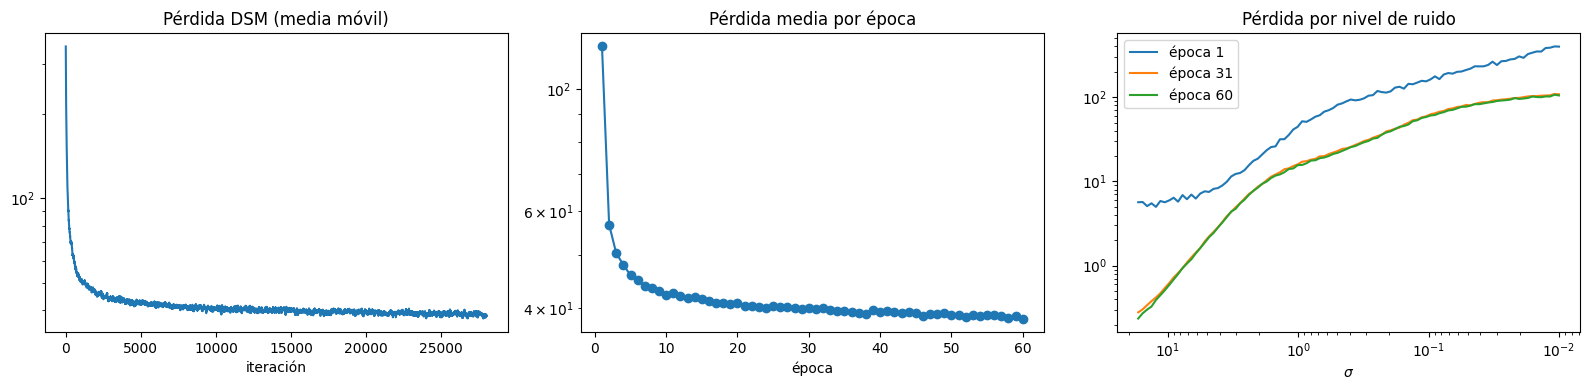

In [ ]:
def smooth(v, w=50):
    v = np.asarray(v, dtype=float)
    if len(v) < w: return v
    return np.convolve(v, np.ones(w) / w, mode="valid")


fig, ax = plt.subplots(
    1,
    3,
    figsize=(16, 4),
)

ax[0].plot(
    smooth(
        hist_it["loss"]
    )
)
ax[0].set_yscale("log")
ax[0].set_xlabel("iteración")
ax[0].set_title(
    "Pérdida DSM (media móvil)"
)

ax[1].plot(
    hist_ep["epoch"],
    hist_ep["loss"],
    "o-",
)
ax[1].set_yscale("log")
ax[1].set_xlabel("época")
ax[1].set_title(
    "Pérdida media por época"
)

loss_per_sigma = np.array(
    hist_ep["loss_per_sigma"]
)

sigma_values = (
    sigmas.cpu().numpy()
)

for epoch_index in sorted(
    set([
        0,
        len(loss_per_sigma) // 2,
        len(loss_per_sigma) - 1,
    ])
):
    ax[2].loglog(
        sigma_values,
        loss_per_sigma[epoch_index],
        label=(
            f"época "
            f"{hist_ep['epoch'][epoch_index]}"
        ),
    )

ax[2].invert_xaxis()
ax[2].set_xlabel(r"$\sigma$")
ax[2].set_title(
    "Pérdida por nivel de ruido"
)
ax[2].legend()

plt.tight_layout()
plt.show()


## Generación desde ruido y evolución de la cadena

Cada fila representa una muestra; cada columna muestra el estado tras un nivel de ruido. Se conserva el diagnóstico de ruido efectivo.

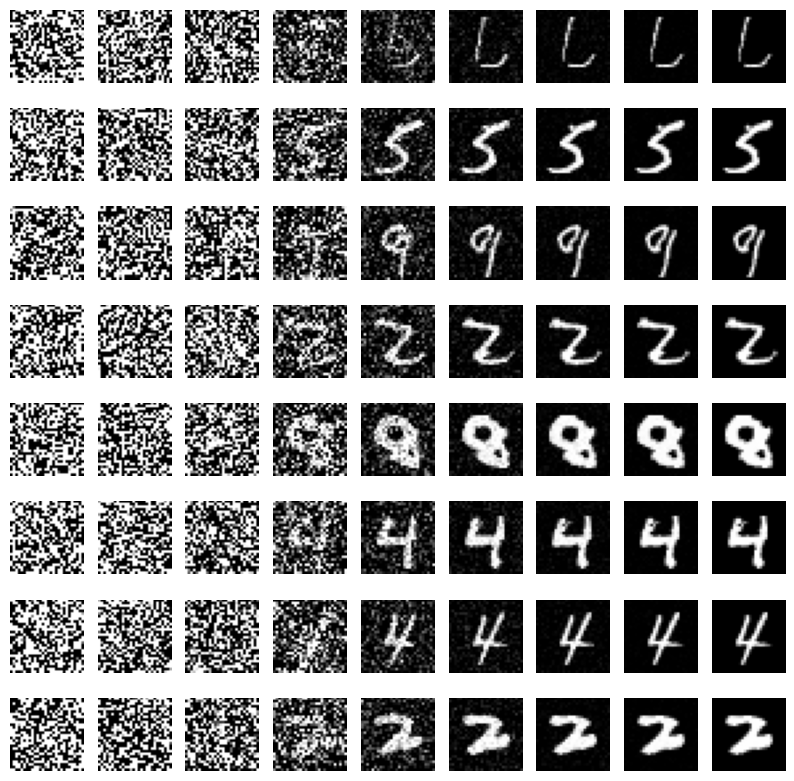

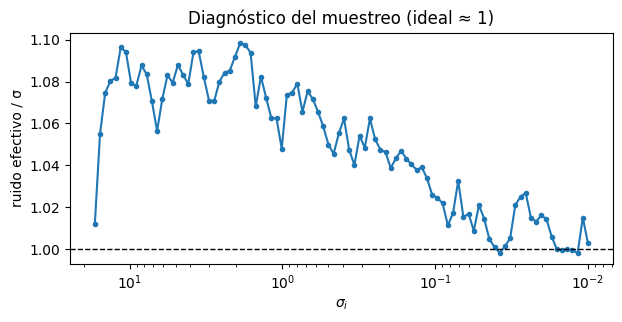

In [9]:
set_seed(123)

levels_to_show = sorted(
    set(
        np.linspace(
            0,
            L - 1,
            8,
        )
        .round()
        .astype(int)
        .tolist()
    )
)

x_final, snapshots, effective_noise = annealed_langevin(
    model=ema,
    n_samples=8,
    seed=123,
    save_levels=levels_to_show,
    **sampler_kwargs,
)

trajectory = torch.stack(
    [
        snapshots[level]
        for level
        in levels_to_show
    ]
    + [x_final],
    dim=-1,
)

_ = plot_image_evolution(
    images=trajectory,
    n_images=8,
    n_intermediate_steps=range(
        len(levels_to_show) + 1
    ),
    figsize=(10, 10),
)

plt.show()

plt.figure(figsize=(7, 3))
plt.semilogx(
    sigmas.cpu().numpy(),
    effective_noise,
    ".-",
)
plt.axhline(
    1,
    color="k",
    ls="--",
    lw=1,
)
plt.gca().invert_xaxis()
plt.xlabel(r"$\sigma_i$")
plt.ylabel("ruido efectivo / σ")
plt.title(
    "Diagnóstico del muestreo "
    "(ideal ≈ 1)"
)
plt.show()


64 muestras en 4.1s (481 evaluaciones de la red por muestra)


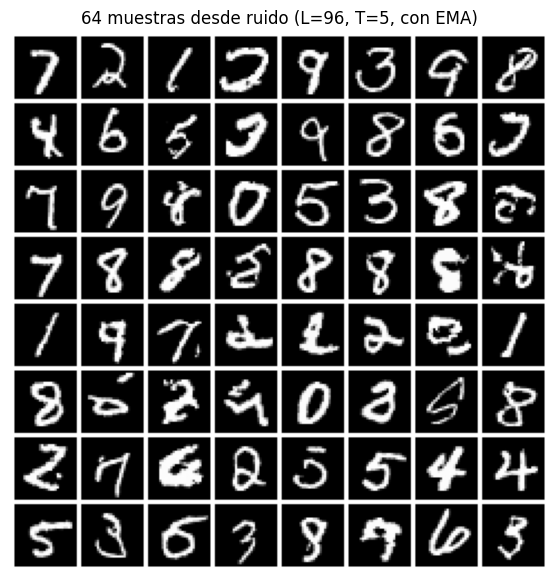

In [10]:
set_seed(7)

t0 = time.time()

x_many = annealed_langevin(
    model=ema,
    n_samples=64,
    seed=7,
    **sampler_kwargs,
)

print(
    f"64 muestras en "
    f"{time.time() - t0:.1f}s "
    f"({NFE} evaluaciones "
    "de la red por muestra)"
)

fig, ax = plot_image_grid(
    images=x_many,
    figsize=(7, 7),
    n_cols=8,
)

ax.set_title(
    f"64 muestras desde ruido "
    f"(L={L}, T={CFG['T']}, con EMA)"
)

plt.show()


## Experimento: cadena larga

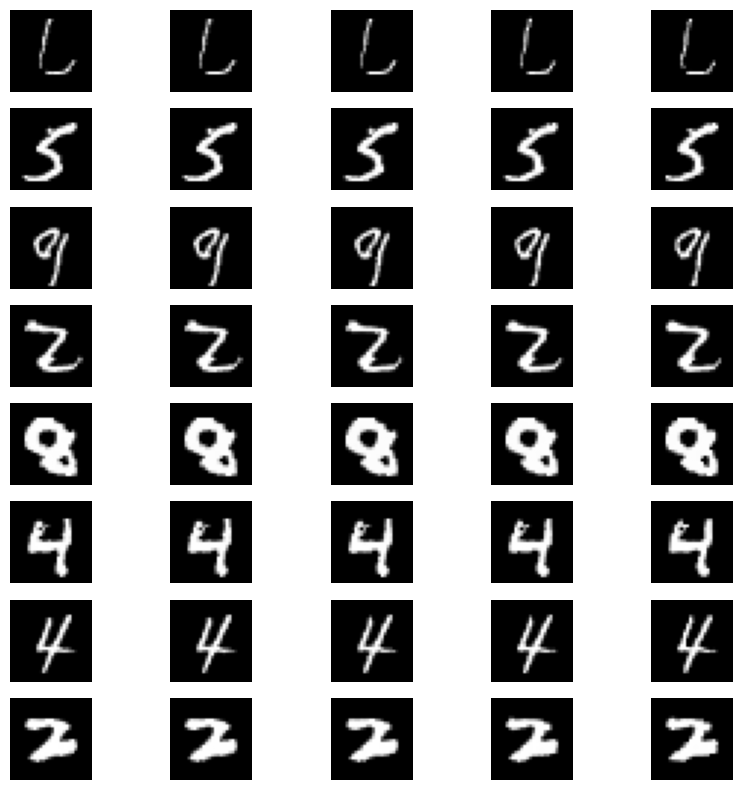

In [11]:
set_seed(11)

long_steps = [
    0,
    100,
    500,
    1000,
    2000,
]

snapshots_long = langevin_at_sigma(
    model=ema,
    x=x_final[:8],
    sigma=sigmas[-1],
    n_steps=max(long_steps),
    step_size=eps,
    save_steps=long_steps,
    device=device,
    seed=11,
)

trajectory_long = torch.stack(
    [
        snapshots_long[step]
        for step
        in long_steps
    ],
    dim=-1,
)

_ = plot_image_evolution(
    images=trajectory_long,
    n_images=8,
    n_intermediate_steps=range(
        len(long_steps)
    ),
    figsize=(10, 10),
)

plt.show()


## Comprobación de ruido

In [12]:
set_seed(7)
N = 512

x_gen = annealed_langevin(
    model=ema,
    n_samples=N,
    seed=7,
    **sampler_kwargs,
)
print(x_gen.shape, x_gen.min().item(), x_gen.max().item())

torch.Size([512, 1, 28, 28]) 0.0 1.0


In [14]:
SIGMA_EVAL = 0.1

reales = []
for xb, _ in test_loader:
    reales.append(xb)
    if sum(t.shape[0] for t in reales) >= N:
        break
x_t = torch.cat(reales)[:N].to(device)
x_gen = x_gen.to(device)

n = min(x_t.shape[0], x_gen.shape[0])

casos = {
    "Imágenes de test":           x_t[:n],
    "Imágenes de test con ruido": x_t[:n] + SIGMA_EVAL * torch.randn_like(x_t[:n]),
    "Muestras generadas":         x_gen[:n],
    "Ruido uniforme":             torch.rand_like(x_t[:n]),
}

ema.eval()
energias = {}
with torch.no_grad():
    for k, v in casos.items():
        s = torch.full((v.shape[0],), SIGMA_EVAL, device=device)
        energias[k] = ema.energy(v, s).flatten().cpu().numpy()

for k, v in energias.items():
    print(f"{k:28s} E media {v.mean():10.2f}   std {v.std():8.2f}")

Imágenes de test             E media     415.85   std    31.18
Imágenes de test con ruido   E media     781.54   std    32.94
Muestras generadas           E media     453.60   std    38.14
Ruido uniforme               E media    1032.08   std    22.18
